In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
from imblearn.over_sampling import RandomOverSampler
from sklearn. preprocessing import StandardScaler
import copy
import seaborn as sns 
import tensorflow as tf
from sklearn.linear_model import LinearRegression 


### Dataset Information

Currently Rental bikes are introduced in many urban cities for the enhancement of mobility comfort. It is important to make the rental bike available and accessible to the public at the right time as it lessens the waiting time. Eventually, providing the city with a stable supply of rental bikes becomes a major concern. The crucial part is the prediction of bike count required at each hour for the stable supply of rental bikes. 
The dataset contains weather information (Temperature, Humidity, Windspeed, Visibility, Dewpoint, Solar radiation, Snowfall, Rainfall), the number of bikes rented per hour and date information. 




In [2]:
dataset_cols = ["bike_count", "hour", "humidity", "wind", "visibility", "dew_pt_temp", "radiation", "rain", "snow", "functional"]

df = pd.read_csv("SeoulBikeData.csv", encoding='latin-1').drop(["Date","Holiday","Seasons"], axis=1)

In [3]:
dataset_cols = ["bike_count", "hour", "temperature", "humidity", "wind", "visibility", "dew_pt_temp", "radiation", "rain", "snow", "functional"]

df.columns = dataset_cols
df["functional"] = (df["functional"] == "Yes").astype(int)

In [4]:
df. columns = dataset_cols
df["functional"] = (df["functional"] =="Yes").astype (int)
df = df [df["hour"] == 12]
df = df.drop([ "hour"], axis=1)

In [5]:
df.head ()

,bike_count,temperature,humidity,wind,visibility,dew_pt_temp,radiation,rain,snow,functional
12,449,1.7,23,1.4,2000,-17.2,1.11,0.0,0.0,0
36,479,4.3,41,1.3,1666,-7.8,1.09,0.0,0.0,0
60,333,5.8,85,1.7,349,3.4,0.43,0.0,0.0,0
84,393,-0.3,38,4.8,1823,-12.9,1.11,0.0,0.0,0
108,321,-2.3,25,0.0,1962,-19.7,0.00,0.0,0.0,0


In [6]:
df = df.drop(["wind","visibility", "functional"], axis=1)

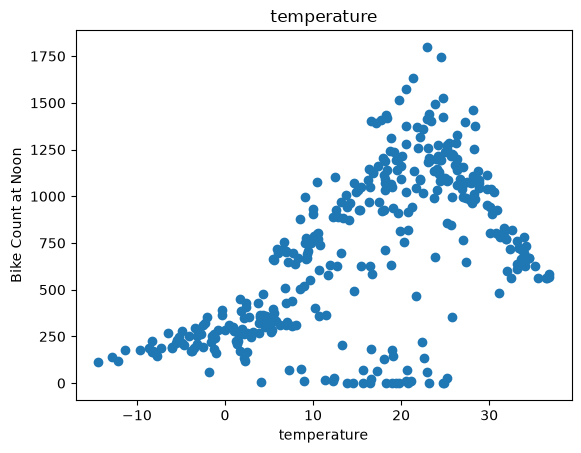

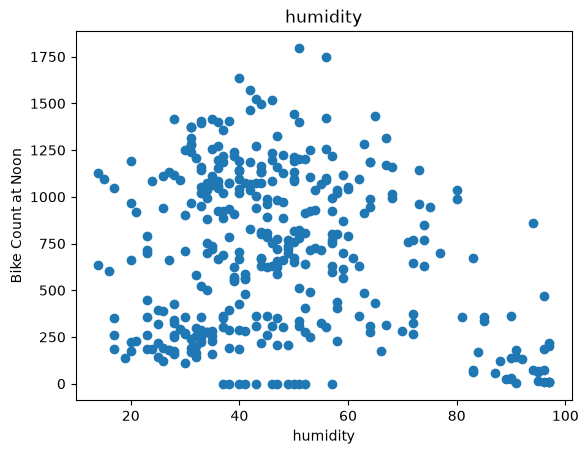

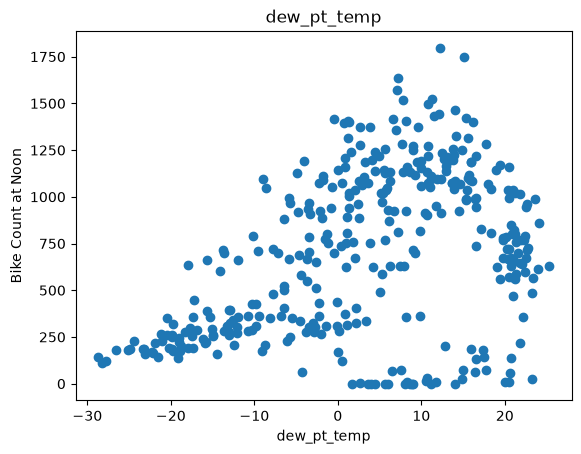

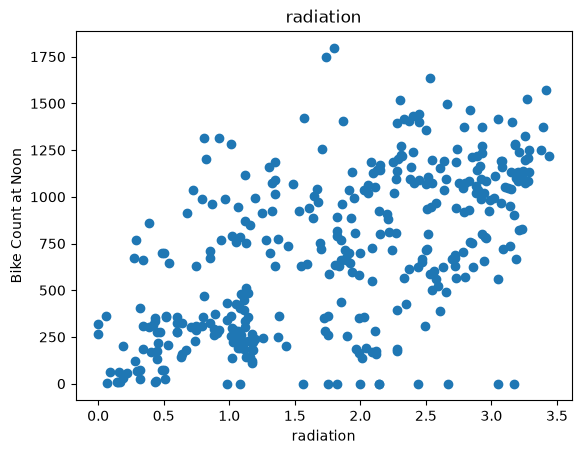

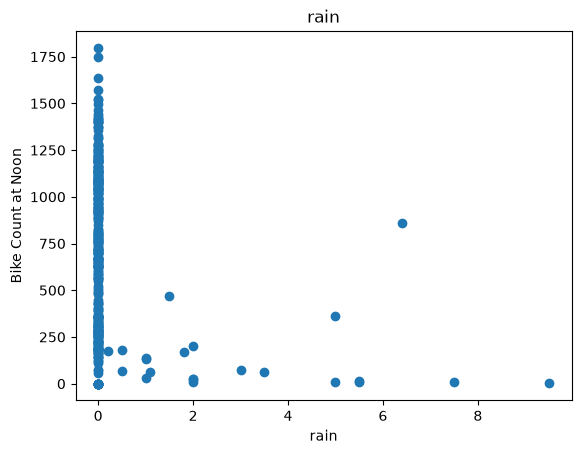

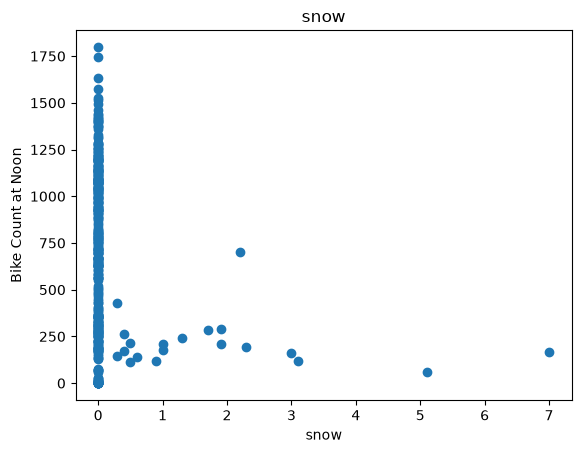

In [7]:
for label in df. columns [1: ]:
 plt.scatter(df[label], df["bike_count"])
 plt. title(label)
 plt.ylabel("Bike Count at Noon")
 plt.xlabel (label)
 plt.show()

In [8]:
df.head()

,bike_count,temperature,humidity,dew_pt_temp,radiation,rain,snow
12,449,1.7,23,-17.2,1.11,0.0,0.0
36,479,4.3,41,-7.8,1.09,0.0,0.0
60,333,5.8,85,3.4,0.43,0.0,0.0
84,393,-0.3,38,-12.9,1.11,0.0,0.0
108,321,-2.3,25,-19.7,0.00,0.0,0.0


## Train / Validate / Test dataset


In [54]:
train, valid, test = np.split(df.sample(frac=1), [int(0.6*len(df)), int(0.8*len(df))])

# Convert the numpy arrays back to Pandas DataFrames
train = pd.DataFrame(train, columns=df.columns)
valid = pd.DataFrame(valid, columns=df.columns)
test = pd.DataFrame(test, columns=df.columns)

In [55]:
import copy

def get_xy(dataframe, y_label, x_labels=None):
    dataframe = copy.deepcopy(dataframe)
    if not x_labels:
        x = dataframe[[c for c in dataframe.columns if c != y_label]].values
    else:
        if len(x_labels) == 1:
            x = dataframe[x_labels[0]].values.reshape(-1, 1)
        else:
            x = dataframe[x_labels].values

    y = dataframe[y_label].values.reshape(-1, 1)
    data = np.hstack((x, y))

    return data, x, y

In [56]:
_, x_train_temp, y_train_temp = get_xy(train, "bike_count", x_labels=["temperature"])
_, x_valid_temp, y_valid_temp = get_xy(valid, "bike_count", x_labels=["temperature"])
_, x_test_temp, y_test_temp = get_xy(test, "bike_count", x_labels=["temperature"])

In [57]:
temp_reg = LinearRegression ()
temp_reg.fit(x_train_temp, y_train_temp)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[21.11]]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[358.42]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[170.53]


In [58]:
temp_reg.score(x_test_temp, y_test_temp)

0.3208928792262292

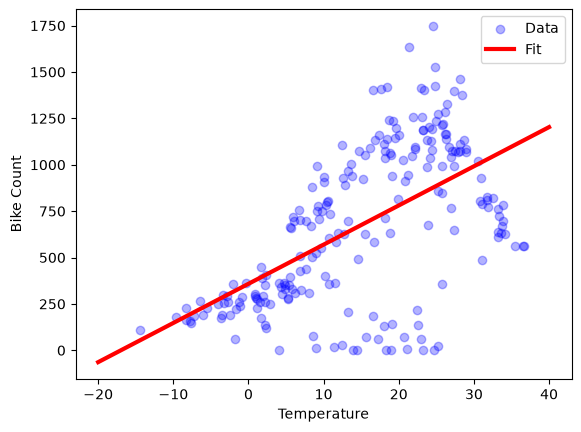

In [59]:
plt.scatter(x_train_temp, y_train_temp, label="Data", color="blue", alpha=0.3)

# Create a range of temperatures to predict on
# np.linspace works better with sklearn than tf.linspace
x = np.linspace(-20, 40, 100).reshape(-1, 1) 
plt.plot(x, temp_reg.predict(x), label="Fit", color="red", linewidth=3)

plt.xlabel("Temperature")
plt.ylabel("Bike Count")
plt.legend()
plt.show()

In [60]:
print (temp_reg.coef_, temp_reg.intercept_)

[[21.11150041]] [358.42086097]


In [61]:
temp_reg. score(x_test_temp, y_test_temp)

0.3208928792262292

## Multiple linear Regression

In [71]:
train, val, test = np.split(df.sample(frac=1), [int(0.6*len(df)), int(0.8*len(df))])

# Convert numpy arrays back to Pandas DataFrames
train = pd.DataFrame(train, columns=df.columns)
val = pd.DataFrame(val, columns=df.columns)
test = pd.DataFrame(test, columns=df.columns)

# Now the get_xy function will work because it can find the column names
_, x_train_all, y_train_all = get_xy(train, "bike_count", x_labels=list(df.columns[1:]))
_, x_val_all, y_val_all = get_xy(val, "bike_count", x_labels=list(df.columns[1:]))
_, x_test_all, y_test_all = get_xy(test, "bike_count", x_labels=list(df.columns[1:]))

In [72]:
all_reg = LinearRegression()
all_reg.fit(x_train_all, y_train_all)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 6)","[[ -8.66, -9.3 , 25.66,150.96,-34.78, -6.06]]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[924.26]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,6
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(6)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](6,)","[308.68,212.5 , 14.72, 10.19, 8.94, 8.21]"


In [73]:
all_reg.score(x_test_all, y_test_all)

0.45958749526767007

## Regression with Neural Net

In [38]:
def plot_loss(history):
    plt.plot(history.history['loss'], label='loss')
    plt.plot(history.history['val_loss'], label='val_loss') # <-- Fixed here
    plt.xlabel('Epoch')
    plt.ylabel('MSE')
    plt.legend()
    plt.grid(True)
    plt.show()

In [39]:
temp_normalizer = tf.keras.layers.Normalization(input_shape=(1,), axis=None)
temp_normalizer.adapt(x_train_temp.reshape(-1))

/Users/manishsingh/Downloads/python/magic+gamma+telescope/.venv/lib/python3.14/site-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [40]:
temp_nn_model = tf.keras.Sequential([
    temp_normalizer,
    tf.keras.layers.Dense(1)
])

In [41]:
temp_nn_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.1), loss='mean_squared_error')

In [42]:
history = temp_nn_model.fit(
x_train_temp.reshape(-1),y_train_temp,
verbose=0, 
epochs=1000, 
validation_data = (x_valid_temp, y_valid_temp)
)

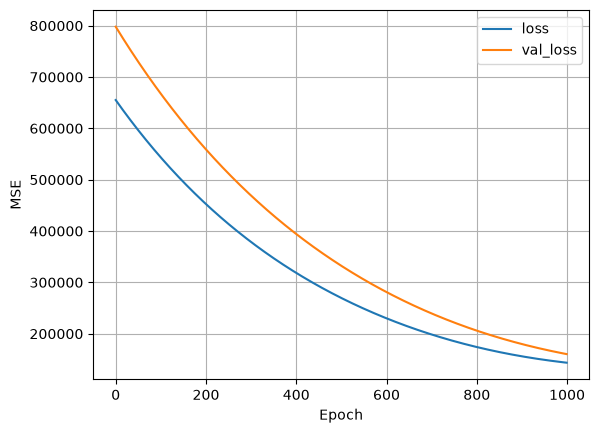

In [44]:
plot_loss(history)

In [26]:
print("Shape of x_train_all:", x_train_all.shape)
print("Shape of y_train_all:", y_train_all.shape)

Shape of x_train_all: (219, 6)
Shape of y_train_all: (219, 1)


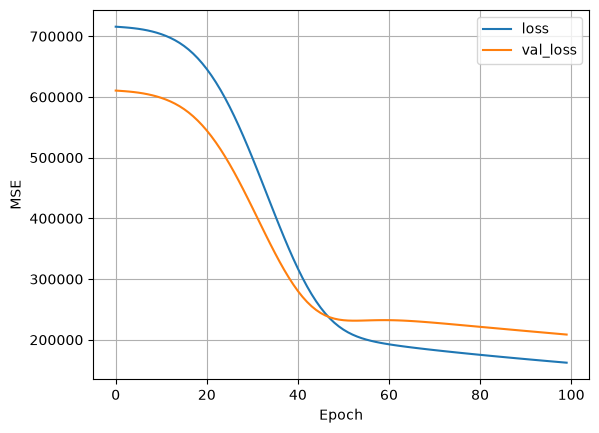

In [45]:
# 1. Normalize the data
all_normalizer = tf.keras.layers.Normalization(axis=None) 
all_normalizer.adapt(x_train_all) 

# 2. Build the model
nn_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(6,)), # <-- CHANGED TO 6 based on your data
    all_normalizer,
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(1)
])

# 3. Compile and Train
nn_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss='mean_squared_error')
history = nn_model.fit(x_train_all, y_train_all, validation_data=(x_val_all, y_val_all), epochs=100, verbose=0)

# 4. Plot
plot_loss(history)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 


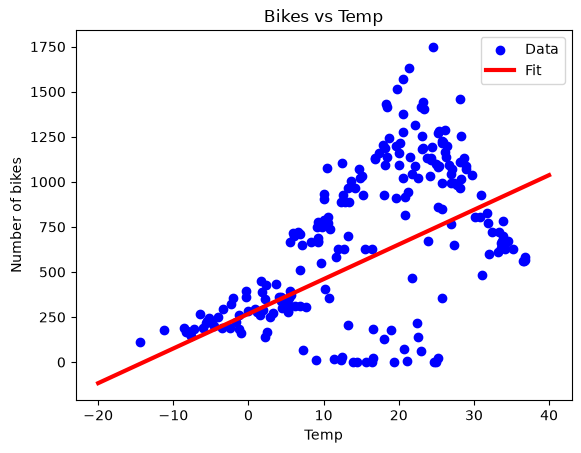

In [46]:
plt.scatter(x_train_temp, y_train_temp, label="Data", color="blue")
X = tf.linspace(-20, 40, 100)
plt.plot(X, temp_nn_model.predict(np.array(X).reshape(-1, 1)), label="Fit", color="red", linewidth=3)
plt.legend()
plt.title("Bikes vs Temp")
plt.ylabel("Number of bikes")
plt.xlabel("Temp")
plt.show()

## Neural Net

In [50]:
nn_model = tf.keras.Sequential([
    temp_normalizer,
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(1)  # <-- Removed activation='relu'
])

nn_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss='mean_squared_error')

In [51]:
history = nn_model. fit (
x_train_temp, y_train_temp,
validation_data= (x_valid_temp, y_valid_temp),
verbose=0, epochs=100
)

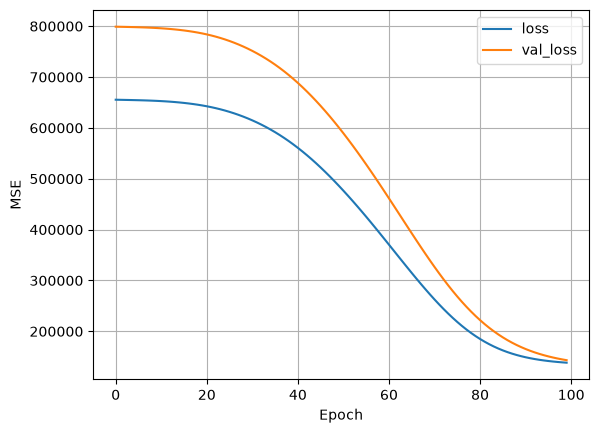

In [52]:
plot_loss(history)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 


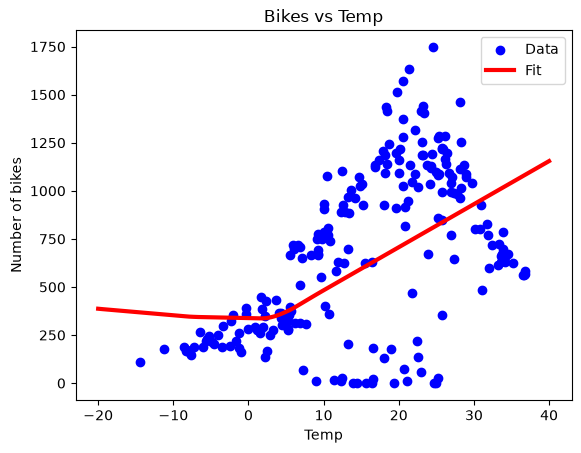

In [53]:
plt.scatter(x_train_temp, y_train_temp, label="Data", color="blue")
X = tf.linspace(-20, 40, 100)
plt.plot(X, nn_model.predict(np.array(X).reshape(-1, 1)), label="Fit", color="red", linewidth=3)
plt.legend()
plt.title("Bikes vs Temp")
plt.ylabel("Number of bikes")
plt.xlabel("Temp")
plt.show()

In [75]:
all_normalizer = tf.keras.layers.Normalization(input_shape=(6,1), axis=-1)
all_normalizer.adapt (x_train_all)

/Users/manishsingh/Downloads/python/magic+gamma+telescope/.venv/lib/python3.14/site-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [76]:
nn_model = tf.keras.Sequential([
all_normalizer,
tf.keras. layers.Dense (32,activation='relu'),
tf.keras. layers. Dense (32, activation='relu'),
tf.keras.layers.Dense (1)
])
nn_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss='mean_squared_error')

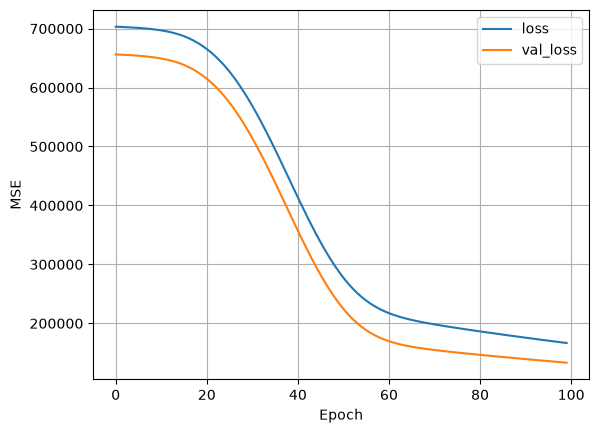

In [81]:
# 1. Create a NEW normalizer for all 6 features
all_normalizer = tf.keras.layers.Normalization(axis=None)
all_normalizer.adapt(x_train_all)

# 2. Build a FRESH model for the multi-feature data
all_nn_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(6,)), # <-- 6 features
    all_normalizer,
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(1) # Linear output for regression
])

# 3. Compile and train the new model
all_nn_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), 
                     loss='mean_squared_error')

history = all_nn_model.fit(
    x_train_all, y_train_all,
    validation_data=(x_val_all, y_val_all),
    epochs=100, 
    verbose=0
)

# 4. Plot the loss
plot_loss(history)

In [86]:
# calculate the MSE for both linear reg and nn
y_pred_lr = all_reg.predict(x_test_all)
y_pred_nn = all_nn_model.predict(x_test_all) # <-- Use the ALL-features model

1/3 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/stepWARNING:tensorflow:6 out of the last 11 calls to <function TensorFlowTrainer.make_predict_function.<locals>.one_step_on_data_distributed at 0x1286b0250> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step


In [87]:
from sklearn.metrics import mean_squared_error

mse_lr = mean_squared_error(y_test_all, y_pred_lr)
mse_nn = mean_squared_error(y_test_all, y_pred_nn)

print(f"Linear Regression MSE: {mse_lr:.2f}")
print(f"Neural Network MSE: {mse_nn:.2f}")

Linear Regression MSE: 99428.73
Neural Network MSE: 156218.87


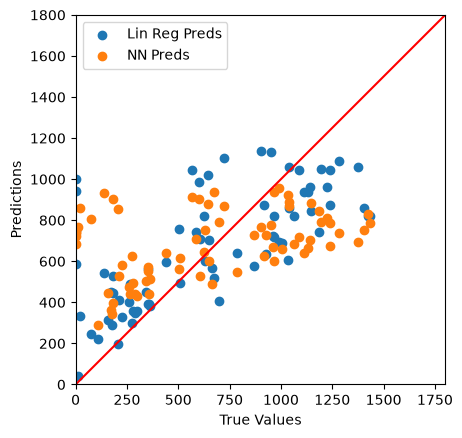

In [91]:

ax = plt.axes(aspect="equal")
plt.scatter(y_test_all, y_pred_lr, label="Lin Reg Preds")
plt.scatter(y_test_all, y_pred_nn, label="NN Preds") # <-- Fixed 'pit' to 'plt'
plt.xlabel("True Values")
plt.ylabel("Predictions")
lims = [0, 1800]
plt.xlim(lims)
plt.ylim(lims)
plt.legend()
_ = plt.plot(lims, lims, c="red")
